# Avance 3 — Entrenamiento, curvas y experimentos

**Clasificación automática de 104 tipos de flores** · TC2035.201 · Tecnológico de Monterrey

Repositorio público: <https://github.com/Lunaaaalj/NeuralNetworksTeamEnvironment>
(este notebook vive en `reports/entregable_3/avance3.ipynb`).

Este notebook reproduce, de principio a fin, las tablas y figuras del reporte del Avance 3:

1. Preparación del entorno y de los datos (TFRecords de Kaggle *Petals to the Metal*).
2. Entrenamiento de la CNN: conjunto completo, subconjuntos aleatorios y conjuntos destilados con
   *Distribution Matching* (DM), más los experimentos de hiperparámetros con el conjunto completo.
3. Re-evaluación de los *checkpoints* guardados sobre las 3,712 imágenes de validación.
4. Tablas de resultados y costos (se escriben en `tablas/` y el reporte LaTeX las incluye).
5. Curvas de aprendizaje de entrenamiento frente a validación (`figures/`).
6. Efecto de los hiperparámetros (tasa de aprendizaje, *dropout* y regularización).

Entrenar todo desde cero toma varias horas en una GPU de Apple, por eso el entrenamiento está detrás de
`RUN_TRAINING = False`. Con la bandera apagada, el notebook usa los historiales (`history.csv`) y resúmenes
(`summary.json`) que se guardaron al entrenar y, si encuentra los *checkpoints*, vuelve a calcular las
métricas de validación para comprobar que coinciden.

## 1. Entorno

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Raíz del repositorio: la carpeta que contiene src/
REPO = Path.cwd().resolve()
while not (REPO / "src").is_dir():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
os.chdir(REPO)

E = REPO / "reports" / "entregable_3"      # evidencia de este avance
FIG, TAB = E / "figures", E / "tablas"
FIG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)

# Los datos (≈2 GB) y los checkpoints no están en git. Por defecto se buscan dentro del repo;
# FLOWERS_DATA_ROOT permite apuntar a otra copia que ya los tenga.
DATA_ROOT = Path(os.environ.get("FLOWERS_DATA_ROOT", REPO))
TFRECORDS = DATA_ROOT / "data/raw/tpu-getting-started/tfrecords-jpeg-224x224"
MODELS = DATA_ROOT / "models"

RUN_TRAINING = False          # True: vuelve a entrenar todo (horas)
EVALUATE_CHECKPOINTS = True   # re-evalúa los .keras guardados si existen

print("Repositorio:", REPO)
print("TFRecords disponibles:", TFRECORDS.exists())
print("Checkpoints disponibles:", MODELS.exists())

Repositorio: /Users/angelluna/Downloads/GitHub/NeuralNetworksTeamEnvironment
TFRecords disponibles: True
Checkpoints disponibles: True


## 2. Datos

Los TFRecords se descargan con la API de Kaggle (requiere `~/.kaggle/kaggle.json` y aceptar las reglas
de la competencia). Cada registro trae la imagen JPEG de 224×224, un `id` y la clase (0–103).

In [2]:
if not TFRECORDS.exists():
    print("Descargar con:  python -m scripts.download_data")
else:
    from src.data import class_counts
    for split in ["train", "val", "test"]:
        n = len(list((TFRECORDS / split).glob("*.tfrec")))
        print(f"{split:5s}: {n} archivos TFRecord")
    counts = class_counts(TFRECORDS, "train")
    print(f"Imágenes de entrenamiento: {counts.sum():,} | por clase: mín {counts.min()}, "
          f"mediana {np.median(counts):.0f}, máx {counts.max()}")

train: 16 archivos TFRecord
val  : 16 archivos TFRecord
test : 16 archivos TFRecord


2026-10-25 22:30:50.294134: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-10-25 22:30:50.294158: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-10-25 22:30:50.294163: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1792989050.294172 4907053 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792989050.294186 4907053 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-10-25 22:30:50.323449: I tensorflow/core/kernels/data/tf_record_dataset_op.cc:370] TFRecordDataset `buffer_size` is unspecified, default to 262144


Imágenes de entrenamiento: 12,753 | por clase: mín 18, mediana 88, máx 782


2026-10-25 22:30:50.507494: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


## 3. Entrenamiento

Configuración del Avance 3 (`reports/entregable_3/config_avance3.yaml`): entrada de 112×112,
Adam con tasa de aprendizaje 1e-3, lotes de 32, *dropout* 0.5, aumento de datos sólo en el conjunto
completo, parada temprana tras 5 evaluaciones sin mejorar el F1 macro de validación y *checkpoint* del
mejor modelo. DM usa 500 iteraciones.

Los experimentos de hiperparámetros (sección 6) parten de una política de referencia (AdamW con
*weight decay* 0.01, reducción de la tasa al estancarse la pérdida, lotes de 64 y paciencia de 12) y
cambian **un solo factor** cada uno; sus configuraciones están en `reports/entregable_3/hiperparametros/*/config.yaml`.

In [3]:
from src.config import load_config
from src.model import build_cnn

cfg = load_config(E / "config_avance3.yaml")
model = build_cnn(cfg["data"]["num_classes"], input_shape=(112, 112, 3))
print(f"Parámetros entrenables: {model.count_params():,}")
model.summary()

Parámetros entrenables: 480,936


Model: "flower_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 112, 112, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 104)            │        26,728 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,936 (1.83 MB)

 Trainable params: 480,936 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
def sh(*args):
    print("$", " ".join(args))
    subprocess.run([sys.executable, "-m", *args], cwd=REPO, check=True)

if RUN_TRAINING:
    # 1) Conjunto completo + subconjuntos aleatorios y destilados (IPC 1 y 10, semillas 0-2)
    sh("scripts.run_experiments", "--config", str(E / "config_avance3.yaml"))
    # 2) Hiperparámetros con el conjunto completo (un factor a la vez)
    sh("scripts.run_final", "--only", "referencia", "lr_3e-4", "dropout_0.3", "sin_regularizacion")
else:
    print("RUN_TRAINING = False: se usan los historiales guardados en reports/entregable_3/")

RUN_TRAINING = False: se usan los historiales guardados en reports/entregable_3/


## 4. Re-evaluación de los checkpoints

Se carga cada modelo guardado y se predice el conjunto de validación completo. Si el F1 macro
recalculado coincide con el registrado al entrenar, la tabla de resultados es reproducible.

In [5]:
results = pd.read_csv(E / "resultados.csv")
results["ipc"] = results["ipc"].fillna(0).astype(int)

def reevaluate(results):
    import keras
    from src.data import build_dataset
    from src.metrics import f1_macro, predict_labels
    val = build_dataset(TFRECORDS, "val", 112, 128, cache=True)
    rows = []
    for run in results["run"]:
        path = MODELS / f"{run}.keras"
        if not path.exists():
            continue
        y_true, y_pred, loss = predict_labels(keras.models.load_model(path), val)
        rows.append({"run": run, "f1_recalculado": round(f1_macro(y_true, y_pred), 4),
                     "exactitud_recalculada": round(float(np.mean(y_true == y_pred)), 4),
                     "imagenes_val": len(y_true)})
    return pd.DataFrame(rows)

if EVALUATE_CHECKPOINTS and MODELS.exists() and TFRECORDS.exists():
    check = results[["run", "val_f1_macro", "val_accuracy"]].merge(reevaluate(results), on="run")
    check["diferencia_f1"] = (check["f1_recalculado"] - check["val_f1_macro"]).round(4)
    check.to_csv(E / "reevaluacion.csv", index=False)
    display(check)
    print("Diferencia máxima de F1:", check["diferencia_f1"].abs().max())
else:
    print("Sin datos o checkpoints locales: se omite la re-evaluación.")

2026-10-25 22:30:52.914908: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


2026-10-25 22:30:55.218136: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


2026-10-25 22:30:59.767362: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,run,val_f1_macro,val_accuracy,f1_recalculado,exactitud_recalculada,imagenes_val,diferencia_f1
0,random_ipc1_res112_s0,0.0519,0.0533,0.0519,0.0533,3712,0.0
1,random_ipc1_res112_s1,0.0483,0.0544,0.0483,0.0544,3712,0.0
2,random_ipc1_res112_s2,0.0540,0.0649,0.0540,0.0649,3712,0.0
3,random_ipc10_res112_s0,0.2641,0.2686,0.2641,0.2686,3712,0.0
4,random_ipc10_res112_s1,0.2602,0.2624,0.2602,0.2624,3712,0.0
5,random_ipc10_res112_s2,0.2483,0.2449,0.2483,0.2449,3712,0.0
6,distilled_ipc1_res112_s0,0.0625,0.0999,0.0625,0.0999,3712,0.0
7,distilled_ipc1_res112_s1,0.0662,0.0884,0.0662,0.0884,3712,0.0
8,distilled_ipc1_res112_s2,0.0728,0.1072,0.0728,0.1072,3712,0.0
9,distilled_ipc10_res112_s0,0.2170,0.2107,0.2170,0.2107,3712,0.0


Diferencia máxima de F1: 0.0


## 5. Tablas de resultados

In [6]:
NAMES = {"full": "Conjunto completo", "random": "Aleatorio", "distilled": "Destilado (DM)"}
ORDER = [("random", 1), ("distilled", 1), ("random", 10), ("distilled", 10), ("full", 0)]

agg = (results.groupby(["data", "ipc"])
       .agg(corridas=("seed", "count"), f1=("val_f1_macro", "mean"), f1_std=("val_f1_macro", "std"),
            exactitud=("val_accuracy", "mean"), entrenamiento_s=("train_seconds", "mean"),
            destilacion_s=("distill_seconds", "first"), epocas=("epochs_run", "mean"),
            mejor_epoca=("best_epoch", "mean"))
       .reindex(ORDER))
agg.to_csv(E / "resumen_avance3.csv")
display(agg.round(4))

def fmt_f1(r):
    return f"{r.f1:.4f} $\\pm$ {r.f1_std:.4f}" if r.corridas > 1 else f"{r.f1:.4f}"

lines = []
for (data, ipc), r in agg.iterrows():
    lines.append(f"{NAMES[data]} & {ipc or '--'} & {int(r.corridas)} & {fmt_f1(r)} & "
                 f"{100 * r.exactitud:.2f} & {r.entrenamiento_s:,.1f} \\\\")
(TAB / "resultados.tex").write_text("\n".join(lines) + "\n\\bottomrule\n")

lines = []
for (data, ipc), r in agg.iterrows():
    d = r.destilacion_s
    total = r.entrenamiento_s + (0 if np.isnan(d) else d)
    lines.append(f"{NAMES[data]} & {ipc or '--'} & {r.entrenamiento_s:,.1f} & "
                 f"{'--' if np.isnan(d) else f'{d:,.1f}'} & {total:,.1f} \\\\")
(TAB / "costos.tex").write_text("\n".join(lines) + "\n\\bottomrule\n")
print((TAB / "resultados.tex").read_text())

,,corridas,f1,f1_std,exactitud,entrenamiento_s,destilacion_s,epocas,mejor_epoca
data,ipc,,,,,,,,
random,1,3,0.0514,0.0029,0.0575,35.3667,NaN,270.0000,226.6667
distilled,1,3,0.0672,0.0052,0.0985,36.2667,985.4,273.3333,226.6667
random,10,3,0.2575,0.0082,0.2586,329.4333,NaN,290.0000,256.6667
distilled,10,3,0.2044,0.0235,0.2055,272.5000,1510.0,250.0000,203.3333
full,0,1,0.5538,NaN,0.6161,581.5000,NaN,43.0000,38.0000


Aleatorio & 1 & 3 & 0.0514 $\pm$ 0.0029 & 5.75 & 35.4 \\
Destilado (DM) & 1 & 3 & 0.0672 $\pm$ 0.0052 & 9.85 & 36.3 \\
Aleatorio & 10 & 3 & 0.2575 $\pm$ 0.0082 & 25.86 & 329.4 \\
Destilado (DM) & 10 & 3 & 0.2044 $\pm$ 0.0235 & 20.55 & 272.5 \\
Conjunto completo & -- & 1 & 0.5538 & 61.61 & 581.5 \\
\bottomrule



## 6. Curvas de aprendizaje

Las métricas de entrenamiento de `history.csv` se registran durante cada época, con aumento de datos y
*dropout* activos; las de validación se calculan al final de la época sin aumentos. En los conjuntos
reducidos, validación sólo se mide cada 10 épocas, así que esas curvas se trazan con marcadores en las
épocas evaluadas, sin interpolar las demás.

 epoch  accuracy  loss  val_accuracy  val_f1_macro  val_loss
     1     0.088 3.939         0.130         0.022     3.588
    10     0.369 2.341         0.402         0.231     2.238
    20     0.518 1.738         0.526         0.414     1.785
    30     0.614 1.362         0.603         0.522     1.546
    38     0.660 1.163         0.616         0.554     1.510
    43     0.681 1.074         0.626         0.550     1.564


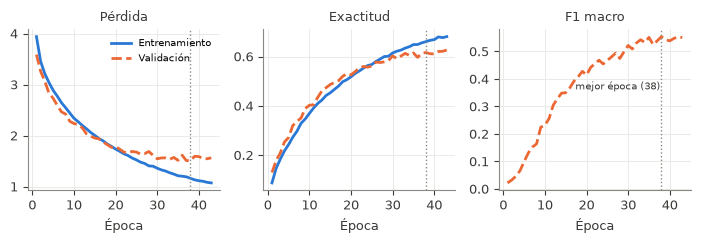

In [7]:
TRAIN_C, VAL_C = "#2a78d6", "#eb6834"   # paleta categórica validada (slots 1 y 2)
INK, MUTED = "#3a3a38", "#8a8a85"
plt.rcParams.update({
    "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "legend.frameon": False,
    "lines.linewidth": 2, "savefig.bbox": "tight", "font.family": "DejaVu Sans",
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=200)

def history(run):
    h = pd.read_csv(E / "runs" / run / "history.csv")
    h["epoch"] += 1   # épocas desde 1, como best_epoch en summary.json
    return h

full = history("full_res112_s0")
best = json.loads((E / "runs/full_res112_s0/summary.json").read_text())["best_epoch"]

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.5))
for ax, (tr, va, title) in zip(axes, [("loss", "val_loss", "Pérdida"),
                                      ("accuracy", "val_accuracy", "Exactitud"),
                                      (None, "val_f1_macro", "F1 macro")]):
    if tr:
        ax.plot(full.epoch, full[tr], color=TRAIN_C, label="Entrenamiento")
    ax.plot(full.epoch, full[va], color=VAL_C, linestyle="--", label="Validación")
    ax.axvline(best, color=MUTED, linewidth=1, linestyle=":")
    ax.set_title(title, fontsize=9, color=INK)
    ax.set_xlabel("Época")
axes[2].annotate(f"mejor época ({best})", (best, full.val_f1_macro.max()), xytext=(-62, -38),
                 textcoords="offset points", fontsize=7, color=INK)
axes[0].legend(fontsize=7, loc="upper right")
fig.tight_layout()
save(fig, "curvas_completo")
print(full.loc[[0, 9, 19, 29, best - 1, len(full) - 1]].round(3).to_string(index=False))

,train_acc,val_acc,train_loss,val_loss
config,,,,
distilled ipc1,0.596,0.091,1.189,13.453
distilled ipc10,0.743,0.196,0.808,8.501
random ipc1,0.744,0.055,0.757,15.973
random ipc10,0.832,0.254,0.531,8.011


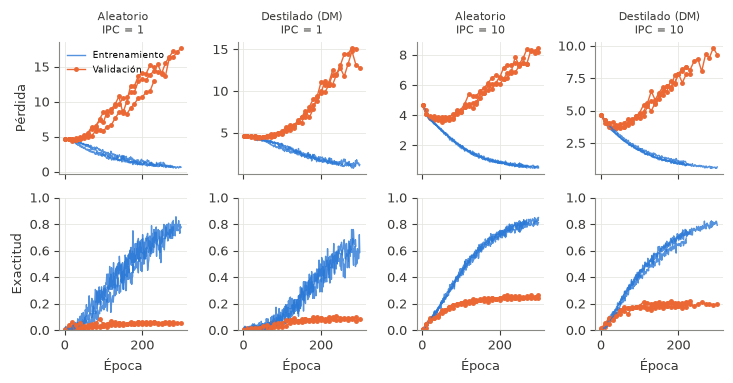

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(7.4, 3.9), sharex=True)
for col, (data, ipc) in enumerate(ORDER[:4]):
    for seed in range(3):
        h = history(f"{data}_ipc{ipc}_res112_s{seed}")
        v = h.dropna(subset=["val_loss"])
        lab = seed == 0
        axes[0, col].plot(h.epoch, h.loss, color=TRAIN_C, linewidth=1, alpha=0.8,
                          label="Entrenamiento" if lab else None)
        axes[0, col].plot(v.epoch, v.val_loss, color=VAL_C, linewidth=1, marker="o", markersize=2.5,
                          label="Validación" if lab else None)
        axes[1, col].plot(h.epoch, h.accuracy, color=TRAIN_C, linewidth=1, alpha=0.8)
        axes[1, col].plot(v.epoch, v.val_accuracy, color=VAL_C, linewidth=1, marker="o", markersize=2.5)
    axes[0, col].set_title(f"{NAMES[data]}\nIPC = {ipc}", fontsize=8, color=INK)
    axes[1, col].set_xlabel("Época")
    axes[1, col].set_ylim(0, 1)
axes[0, 0].set_ylabel("Pérdida"); axes[1, 0].set_ylabel("Exactitud")
axes[0, 0].legend(fontsize=6.5, loc="upper left")
fig.tight_layout()
save(fig, "curvas_reducidos")

last = []
for data, ipc in ORDER[:4]:
    for seed in range(3):
        h = history(f"{data}_ipc{ipc}_res112_s{seed}").dropna(subset=["val_loss"]).iloc[-1]
        last.append({"config": f"{data} ipc{ipc}", "seed": seed, "train_acc": h.accuracy,
                     "val_acc": h.val_accuracy, "train_loss": h.loss, "val_loss": h.val_loss})
display(pd.DataFrame(last).groupby("config").mean().drop(columns="seed").round(3))

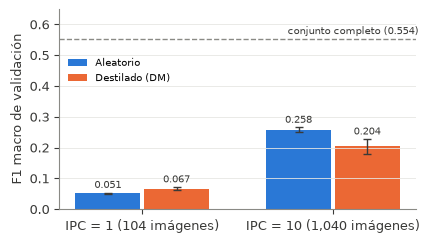

In [9]:
fig, ax = plt.subplots(figsize=(4.6, 2.6))
x = np.arange(2)
for i, data in enumerate(["random", "distilled"]):
    sub = agg.loc[[(data, 1), (data, 10)]]
    ax.bar(x + (i - 0.5) * 0.36, sub.f1, 0.34, yerr=sub.f1_std, capsize=3,
           color=[TRAIN_C, VAL_C][i], label=NAMES[data], error_kw={"elinewidth": 1, "ecolor": INK})
    for xi, v, s in zip(x + (i - 0.5) * 0.36, sub.f1, sub.f1_std):
        ax.text(xi, v + s + 0.015, f"{v:.3f}", ha="center", fontsize=7, color=INK)
ax.axhline(agg.loc[("full", 0), "f1"], color=MUTED, linestyle="--", linewidth=1)
ax.text(1.45, agg.loc[("full", 0), "f1"] + 0.015, "conjunto completo (0.554)", ha="right", fontsize=7, color=INK)
ax.set_xticks(x, ["IPC = 1 (104 imágenes)", "IPC = 10 (1,040 imágenes)"])
ax.set_ylabel("F1 macro de validación"); ax.set_ylim(0, 0.65)
ax.grid(axis="x", visible=False); ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(0, 0.8))
save(fig, "comparacion_f1")

## 7. Experimentos de hiperparámetros (conjunto completo)

Cada experimento cambia un solo factor respecto a la referencia. Aquí las métricas de entrenamiento
se miden igual que las de validación (3,712 imágenes de entrenamiento fijas, sin aumentos ni *dropout*),
por lo que la brecha entre ambas sí indica sobreajuste.

In [10]:
HP = [("referencia", "Referencia (LR $10^{-3}$, dropout 0.5)"),
      ("lr_3e-4", "Tasa de aprendizaje $3\\times10^{-4}$"),
      ("dropout_0.3", "Dropout 0.3"),
      ("sin_regularizacion", "Sin dropout, aumento ni weight decay")]
rows, hists = [], {}
for key, label in HP:
    s = json.loads((E / "hiperparametros" / key / "summary.json").read_text())
    h = pd.read_csv(E / "hiperparametros" / key / "history.csv"); h["epoch"] += 1
    hists[key] = h
    b = h.loc[h.epoch == s["best_epoch"]].iloc[0]
    rows.append({"experimento": key, "etiqueta": label, "lr": s["lr"], "dropout": s["dropout"],
                 "aumento": s["augment"], "optimizador": s["optimizer"], "epocas": s["epochs_run"],
                 "mejor_epoca": s["best_epoch"], "f1_val": s["val_f1_macro"], "exactitud_val": s["val_accuracy"],
                 "f1_train": round(b.train_f1_macro, 4), "brecha_f1": round(b.train_f1_macro - b.val_f1_macro, 4),
                 "val_loss_min": round(h.val_loss.min(), 3), "segundos": s["train_seconds"]})
hp = pd.DataFrame(rows)
hp.to_csv(E / "hiperparametros.csv", index=False)
display(hp.drop(columns="etiqueta"))

lines = [f"{r.etiqueta} & {r.f1_val:.4f} & {100 * r.exactitud_val:.2f} & {r.f1_train:.3f} & "
         f"{r.brecha_f1:.3f} & {r.mejor_epoca} / {r.epocas} \\\\" for r in hp.itertuples()]
(TAB / "hiperparametros.tex").write_text("\n".join(lines) + "\n\\bottomrule\n")

,experimento,lr,dropout,aumento,optimizador,epocas,mejor_epoca,f1_val,exactitud_val,f1_train,brecha_f1,val_loss_min,segundos
0,referencia,0.0010,0.5,True,adamw,103,91,0.5784,0.6406,0.8138,0.2354,1.464,1181.6
1,lr_3e-4,0.0003,0.5,True,adamw,110,98,0.4605,0.5418,0.5541,0.0936,1.776,1350.8
2,dropout_0.3,0.0010,0.3,True,adamw,73,61,0.5596,0.6196,0.8157,0.2560,1.596,901.3
3,sin_regularizacion,0.0010,0.0,False,adam,46,34,0.5332,0.5964,0.8767,0.3435,1.825,540.5


323

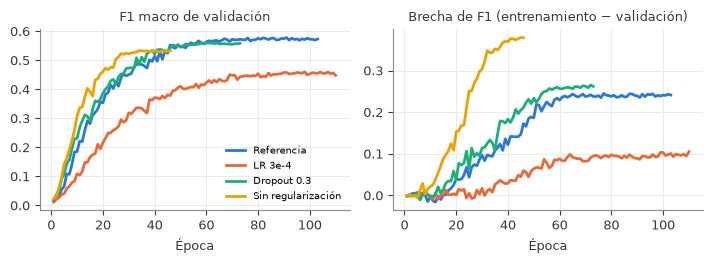

In [11]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # validada: CVD ΔE ≥ 9
SHORT = {"referencia": "Referencia", "lr_3e-4": "LR 3e-4", "dropout_0.3": "Dropout 0.3",
         "sin_regularizacion": "Sin regularización"}
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.7))
for (key, _), c in zip(HP, COLORS):
    h = hists[key]
    axes[0].plot(h.epoch, h.val_f1_macro, color=c, label=SHORT[key])
    axes[1].plot(h.epoch, h.train_f1_macro - h.val_f1_macro, color=c, label=SHORT[key])
axes[0].set_title("F1 macro de validación", fontsize=9, color=INK)
axes[1].set_title("Brecha de F1 (entrenamiento − validación)", fontsize=9, color=INK)
for ax in axes: ax.set_xlabel("Época")
axes[0].legend(fontsize=7, loc="lower right")
fig.tight_layout()
save(fig, "curvas_hiperparametros")